# Hands-on 15: Fitur Getaran Sederhana untuk Deteksi Kondisi Mesin

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 5.

Fitur per jendela (window=50, step=25) dari `data/synthetic/vibration_fault_injection.csv`:
mean, std, min, max, range, RMS, peak-to-peak, kurtosis. Label mayoritas per jendela.
Output: `data/processed/vibration_window_features.csv` (119 jendela: 58 normal, 61 fault).

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Ekstraksi Fitur per Jendela

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/feature_vibration_machine.py"], capture_output=True, text=True)
print(r.stdout)

[SUKSES] Fitur getaran disimpan ke: data/processed/vibration_window_features.csv (119 jendela)
   window_start  window_end machine_id  ...       rms  peak_to_peak  kurtosis
0             0          49    motor01  ...  0.584026       1.86925  1.835616
1            25          74    motor01  ...  0.576109       1.87356  1.538758
2            50          99    motor01  ...  0.565299       1.73413  1.942882
3            75         124    motor01  ...  0.576829       1.75879  1.515197
4           100         149    motor01  ...  0.579784       1.80485  1.992898

[5 rows x 12 columns]

[INFO] Distribusi label:
status_label
fault     61
normal    58
Name: count, dtype: int64



## 2. Visualisasi Fitur

[SUKSES] outputs/figures/vibration_window_features.png



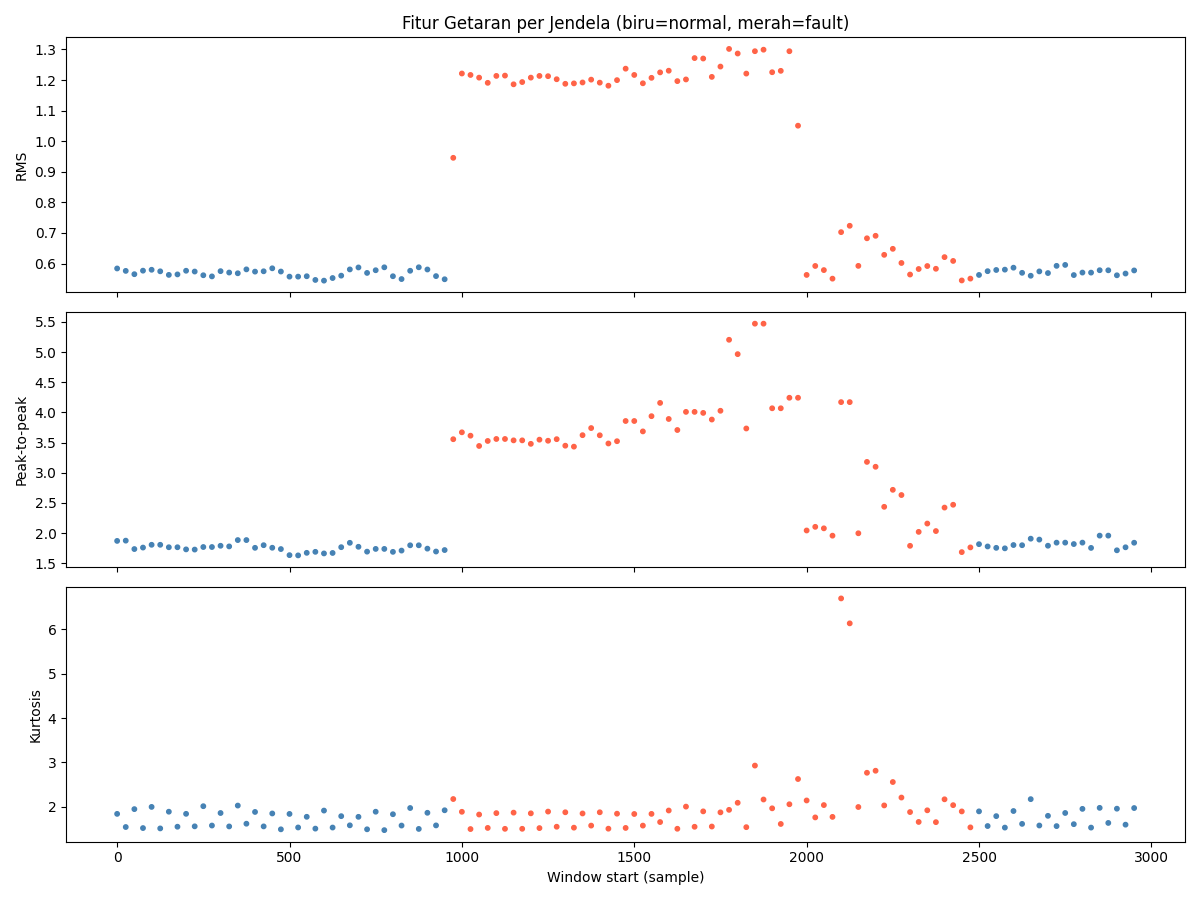

In [3]:
r = subprocess.run([sys.executable, "scripts/plot_vibration_features.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/vibration_window_features.png")

## Penutup

RMS dan peak-to-peak naik jelas di zona fault; kurtosis melonjak di area spike. Fitur
jendela ini menjadi input klasifikasi status mesin (Hands-on 24) dan studi kasus
predictive maintenance (Hands-on 36).

## Figur persis sesuai buku (Hands-on 15)

`scripts/book_figures.py --only rmsstd` membuat `outputs/figures/vibration_features_rms_std.png` dengan judul, label sumbu, dan ukuran sesuai listing buku.

[SUKSES] figur 'rmsstd' dibuat di outputs/figures
 


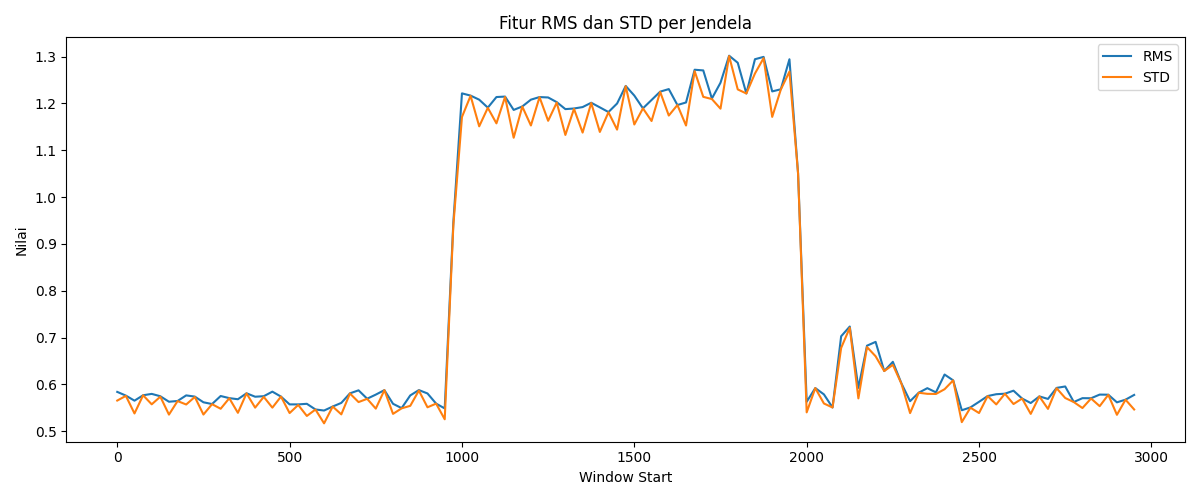

In [4]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/book_figures.py", "--only", "rmsstd"], capture_output=True, text=True)
print(r.stdout, r.stderr)
from IPython.display import Image, display
display(Image("outputs/figures/vibration_features_rms_std.png"))